# Week 6: Exploratory Data Analysis (EDA) & Class Distribution Analysis

**Project Title:** Hybrid ML-Based Intrusion Detection System  
**Project ID:** SKIT/IOT/2023-2027/F-031  
**Role:** Nancy — Machine Learning and ML-related backend  
**Current Week:** Week 6  

---

## Objectives for Week 6
1. Perform separate, comprehensive Exploratory Data Analysis (EDA) on **CICIDS2017** and **CIC-IoT2023**.
2. Inspect shapes, schemas, feature types, missing values, infinite values, and duplicates.
3. Analyze ground-truth target labels (`Label` in CICIDS2017 and `Attack_Category` derived from parent directory in CIC-IoT2023).
4. Quantify class imbalance and evaluate its impact on supervised classification.
5. Visualize class distributions, feature distributions, and correlation structures.
6. Provide actionable interpretations for designing the **Hybrid FT-Transformer + Autoencoder** architecture.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

# Set style for plots
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({"font.size": 10, "axes.labelsize": 11, "axes.titlesize": 12})

# Add project root to Python path
PROJECT_ROOT = Path.cwd().parent if (Path.cwd().parent / "ml").exists() else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from ml.data.load_dataset import load_dataset_folder, validate_dataset
from ml.data.clean import standardize_column_names, replace_infinite_values
from ml.data.preprocess import add_iot_attack_category

print("Project Root:", PROJECT_ROOT)

Project Root: D:\Project-root\SKIT-IOT-2023-2027-F-031


## 1. Load ML Configuration & Define Data Paths

We load paths and parameters from `configs/ml_config.yaml` to avoid hardcoding personal local paths.

In [2]:
config_path = PROJECT_ROOT / "configs" / "ml_config.yaml"
with open(config_path, "r") as f:
    config = yaml.safe_load(f)

CICIDS_DIR = PROJECT_ROOT / config["datasets"]["cicids2017"]["raw_dir"]
CIC_IOT_DIR = PROJECT_ROOT / config["datasets"]["cic_iot2023"]["raw_dir"]

print(f"CICIDS2017 Directory: {CICIDS_DIR} (Exists: {CICIDS_DIR.exists()})")
print(f"CIC-IoT2023 Directory: {CIC_IOT_DIR} (Exists: {CIC_IOT_DIR.exists()})")

CICIDS2017 Directory: D:\Project-root\SKIT-IOT-2023-2027-F-031\data\raw\CICIDS2017 (Exists: True)
CIC-IoT2023 Directory: D:\Project-root\SKIT-IOT-2023-2027-F-031\data\raw\CIC-IoT2023 (Exists: True)


---
# Part A: CICIDS2017 Exploratory Data Analysis

### A.1 Overview & Sample Loading
The raw CICIDS2017 dataset consists of 8 PCAP-derived CSV files totaling ~2.83M rows (~880 MB). To ensure responsive, memory-safe EDA, we load a balanced sample of 10,000 records from each file (80,000 records total), while preserving full dataset scanning results for exact class counts.

In [3]:
# Load configurable sample from all 8 CSV files of CICIDS2017
SAMPLE_ROWS_CICIDS = 10000
cicids_raw = load_dataset_folder(
    CICIDS_DIR,
    dataset_name="CICIDS2017",
    sample_rows=SAMPLE_ROWS_CICIDS
)

print("Loaded CICIDS2017 sample shape:", cicids_raw.shape)
cicids_df = standardize_column_names(cicids_raw)
print("Standardized columns sample:", cicids_df.columns[:10].tolist())

Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Loading: Monday-WorkingHours.pcap_ISCX.csv
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv


Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Loading: Wednesday-workingHours.pcap_ISCX.csv
Loaded CICIDS2017 sample shape: (80000, 81)
Standardized columns sample: ['Destination_Port', 'Flow_Duration', 'Total_Fwd_Packets', 'Total_Backward_Packets', 'Total_Length_of_Fwd_Packets', 'Total_Length_of_Bwd_Packets', 'Fwd_Packet_Length_Max', 'Fwd_Packet_Length_Min', 'Fwd_Packet_Length_Mean', 'Fwd_Packet_Length_Std']


### A.2 Column Names, Schema, & Data Types

In [4]:
print("Total columns in CICIDS2017:", len(cicids_df.columns))
dtype_counts = cicids_df.dtypes.value_counts()
print("\nData Types Summary:\n", dtype_counts)

# Identify numeric vs non-numeric columns
cicids_numeric = cicids_df.select_dtypes(include=["number"]).columns.tolist()
cicids_non_numeric = cicids_df.select_dtypes(exclude=["number"]).columns.tolist()
print(f"Numeric feature count: {len(cicids_numeric)}")
print(f"Non-numeric columns: {cicids_non_numeric}")

Total columns in CICIDS2017: 81

Data Types Summary:
 int64      54
float64    24
object      3
Name: count, dtype: int64


Numeric feature count: 78
Non-numeric columns: ['Label', 'Source_File', 'Dataset']


### A.3 Data Quality: Missing, Infinite, and Duplicate Values
Network flow extractors (e.g., CICFlowMeter) frequently produce `Infinity` and `NaN` values in flow rate and packet inter-arrival time features due to zero flow durations ($duration = 0$ resulting in division by zero).

In [5]:
# 1. Infinite values check
inf_mask = np.isinf(cicids_df[cicids_numeric])
inf_counts = inf_mask.sum()
inf_cols = inf_counts[inf_counts > 0]
print("Columns containing infinite values:")
print(inf_cols if len(inf_cols) > 0 else "None")

# 2. Missing values check
null_counts = cicids_df.isnull().sum()
null_cols = null_counts[null_counts > 0]
print("\nColumns containing missing (NaN) values:")
print(null_cols if len(null_cols) > 0 else "None")

# 3. Duplicate rows check
num_duplicates = cicids_df.duplicated().sum()
print(f"\nDuplicate rows in sample: {num_duplicates} ({num_duplicates/len(cicids_df)*100:.2f}%)")

Columns containing infinite values:
Flow_Bytes/s      64
Flow_Packets/s    82
dtype: int64

Columns containing missing (NaN) values:
Flow_Bytes/s    18
dtype: int64



Duplicate rows in sample: 979 (1.22%)


### A.4 Descriptive Statistics of Selected Numeric Features
We inspect summary statistics for primary flow metrics: flow duration, packet counts, flow bytes/s, and packet length mean.

In [6]:
# Replace infinities with NaN for valid descriptive stats
cicids_df_clean = replace_infinite_values(cicids_df)

key_cicids_features = [
    "Flow_Duration", "Total_Fwd_Packets", "Total_Backward_Packets",
    "Total_Length_of_Fwd_Packets", "Flow_Bytes/s", "Packet_Length_Mean"
]
cicids_stats = cicids_df_clean[key_cicids_features].describe().T
cicids_stats[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
Flow_Duration,1.702080e+07,3.544105e+07,-1.0,59045.000000,1.200000e+08
Total_Fwd_Packets,5.414344e+01,2.776611e+03,1.0,2.000000,2.197590e+05
Total_Backward_Packets,6.833045e+01,3.693940e+03,0.0,2.000000,2.919220e+05
Total_Length_of_Fwd_Packets,1.093223e+03,1.734178e+04,0.0,76.000000,1.323378e+06
Flow_Bytes/s,1.936838e+06,2.973997e+07,-12000000.0,3561.095398,2.070000e+09
Packet_Length_Mean,1.299563e+02,2.019229e+02,0.0,64.000000,2.058329e+03


### A.5 Target Label Distribution & Class Imbalance Analysis
In CICIDS2017, the target label is stored in the `Label` column. Across the full 2,830,743 records, there are 15 distinct classes with an acute class imbalance.

In [7]:
# Full dataset ground-truth distribution obtained via verification scanner
cicids_full_distribution = {
    "BENIGN": 2273097,
    "DoS Hulk": 231073,
    "PortScan": 158930,
    "DDoS": 128027,
    "DoS GoldenEye": 10293,
    "FTP-Patator": 7938,
    "SSH-Patator": 5897,
    "DoS slowloris": 5796,
    "DoS Slowhttptest": 5499,
    "Bot": 1966,
    "Web Attack - Brute Force": 1507,
    "Web Attack - XSS": 652,
    "Infiltration": 36,
    "Web Attack - Sql Injection": 21,
    "Heartbleed": 11
}

total_cicids = sum(cicids_full_distribution.values())
cicids_dist_df = pd.DataFrame([
    {"Class": k, "Count": v, "Percentage": (v / total_cicids) * 100}
    for k, v in cicids_full_distribution.items()
])
print(cicids_dist_df.to_string(index=False))

# Imbalance ratio: Majority (BENIGN) vs Rarest (Heartbleed)
majority_cnt = cicids_full_distribution["BENIGN"]
minority_cnt = cicids_full_distribution["Heartbleed"]
print(f"\nMajority-to-Minority Imbalance Ratio: {majority_cnt / minority_cnt:,.1f} : 1")

                     Class   Count  Percentage
                    BENIGN 2273097   80.300366
                  DoS Hulk  231073    8.162981
                  PortScan  158930    5.614427
                      DDoS  128027    4.522735
             DoS GoldenEye   10293    0.363615
               FTP-Patator    7938    0.280421
               SSH-Patator    5897    0.208320
             DoS slowloris    5796    0.204752
          DoS Slowhttptest    5499    0.194260
                       Bot    1966    0.069452
  Web Attack - Brute Force    1507    0.053237
          Web Attack - XSS     652    0.023033
              Infiltration      36    0.001272
Web Attack - Sql Injection      21    0.000742
                Heartbleed      11    0.000389

Majority-to-Minority Imbalance Ratio: 206,645.2 : 1


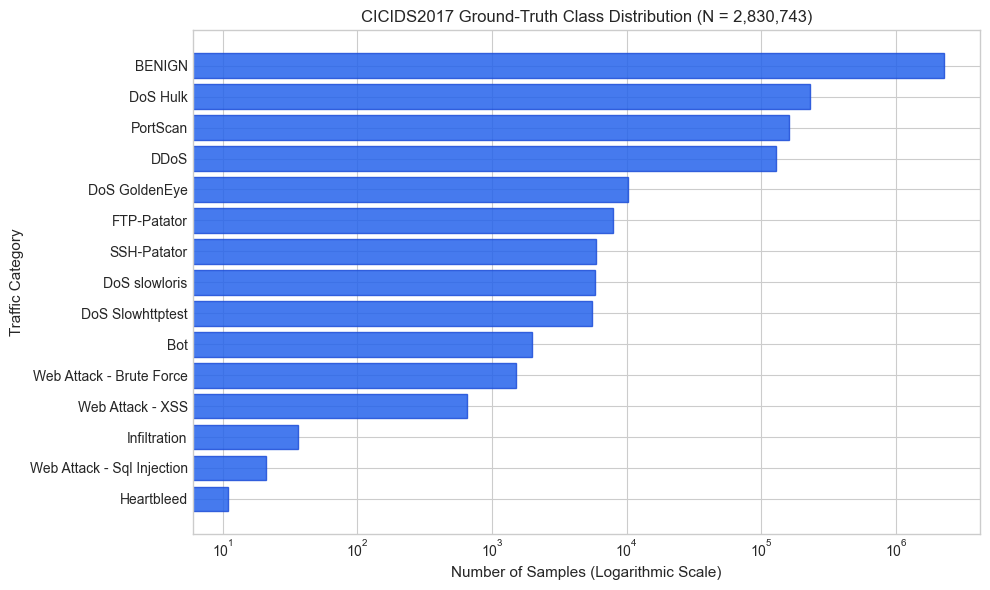

In [8]:
# Class Distribution Visualization (Log-Scaled)
fig, ax = plt.subplots(figsize=(10, 6))
classes = cicids_dist_df["Class"][::-1]
counts = cicids_dist_df["Count"][::-1]

bars = ax.barh(classes, counts, color="#2563EB", edgecolor="#1D4ED8", alpha=0.85)
ax.set_xscale("log")
ax.set_xlabel("Number of Samples (Logarithmic Scale)")
ax.set_ylabel("Traffic Category")
ax.set_title("CICIDS2017 Ground-Truth Class Distribution (N = 2,830,743)")
plt.tight_layout()
plt.show()

### A.6 Feature Distributions for Selected Numeric Attributes
Examining flow distributions reveals significant right-skewness across network traffic features.

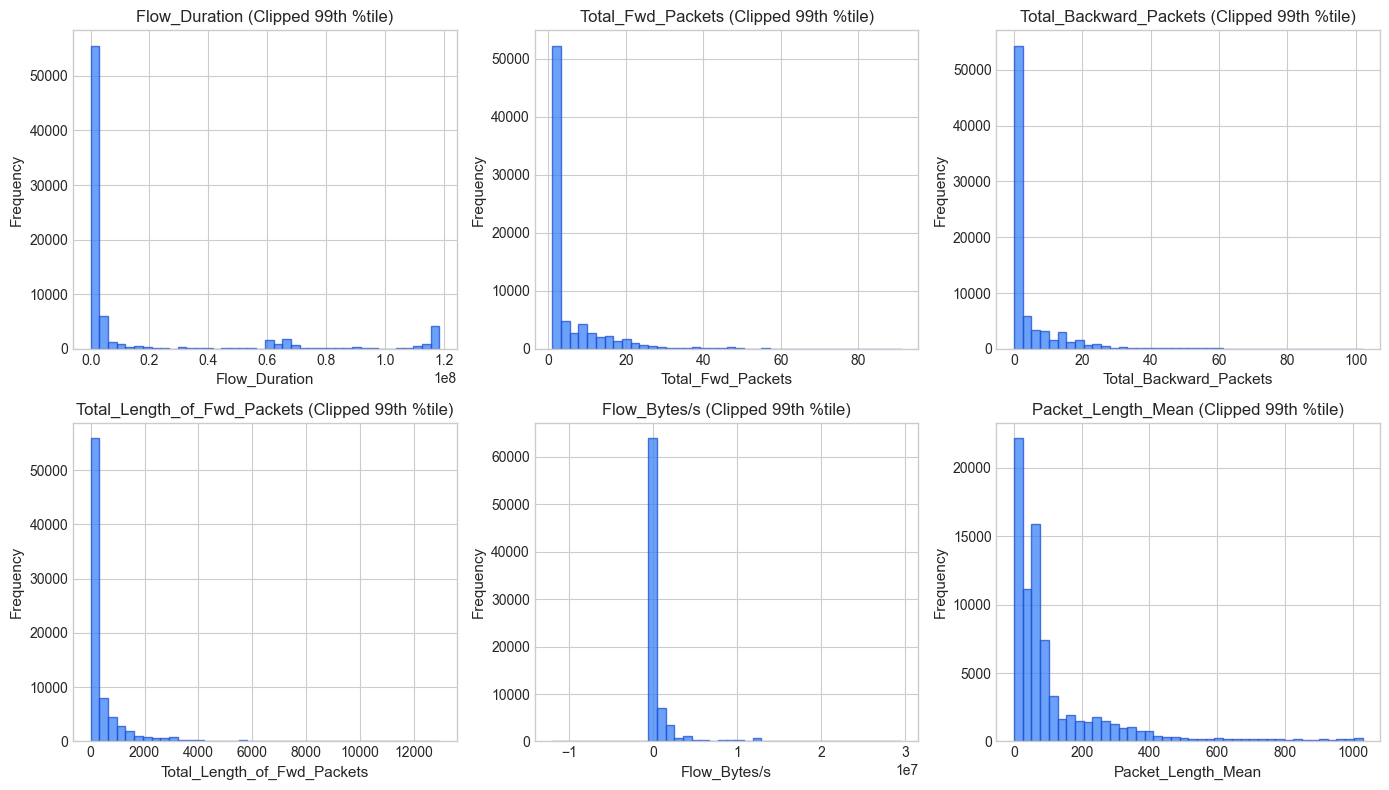

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(key_cicids_features):
    s = cicids_df_clean[col].dropna()
    upper = s.quantile(0.99)
    lower = s.min()
    s_clipped = s[(s >= lower) & (s <= upper)]
    axes[i].hist(s_clipped, bins=40, color="#3B82F6", edgecolor="#1D4ED8", alpha=0.75)
    axes[i].set_title(f"{col} (Clipped 99th %tile)")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### A.7 Correlation Analysis (Selected Flow Features)
We compute the Pearson correlation matrix for a manageable subset of 12 representative flow features to detect multicollinearity without producing excessively large plots.

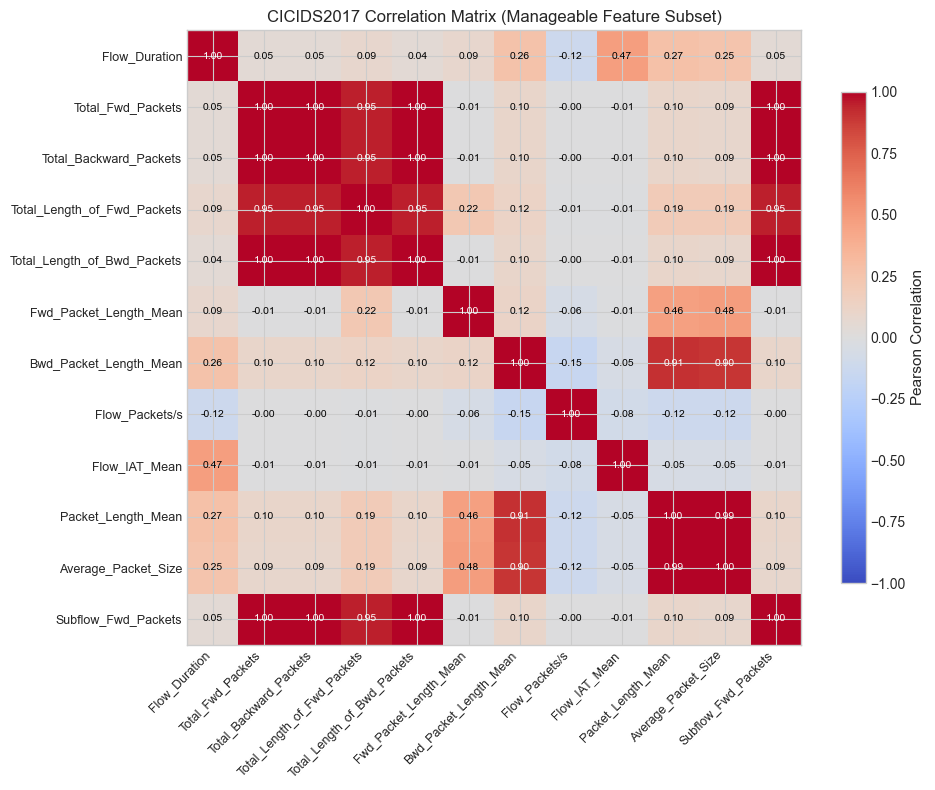

Highly correlated feature pairs (|r| >= 0.85):
  - Total_Fwd_Packets <-> Total_Backward_Packets: r = 1.0
  - Total_Fwd_Packets <-> Total_Length_of_Fwd_Packets: r = 0.952
  - Total_Fwd_Packets <-> Total_Length_of_Bwd_Packets: r = 0.999
  - Total_Fwd_Packets <-> Subflow_Fwd_Packets: r = 1.0
  - Total_Backward_Packets <-> Total_Length_of_Fwd_Packets: r = 0.952
  - Total_Backward_Packets <-> Total_Length_of_Bwd_Packets: r = 1.0
  - Total_Backward_Packets <-> Subflow_Fwd_Packets: r = 1.0
  - Total_Length_of_Fwd_Packets <-> Total_Length_of_Bwd_Packets: r = 0.951
  - Total_Length_of_Fwd_Packets <-> Subflow_Fwd_Packets: r = 0.952
  - Total_Length_of_Bwd_Packets <-> Subflow_Fwd_Packets: r = 0.999
  - Bwd_Packet_Length_Mean <-> Packet_Length_Mean: r = 0.912
  - Bwd_Packet_Length_Mean <-> Average_Packet_Size: r = 0.896
  - Packet_Length_Mean <-> Average_Packet_Size: r = 0.995


In [10]:
corr_features_cicids = [
    "Flow_Duration", "Total_Fwd_Packets", "Total_Backward_Packets",
    "Total_Length_of_Fwd_Packets", "Total_Length_of_Bwd_Packets",
    "Fwd_Packet_Length_Mean", "Bwd_Packet_Length_Mean",
    "Flow_Packets/s", "Flow_IAT_Mean", "Packet_Length_Mean",
    "Average_Packet_Size", "Subflow_Fwd_Packets"
]

corr_matrix_cicids = cicids_df_clean[corr_features_cicids].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_matrix_cicids, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_features_cicids)))
ax.set_yticks(range(len(corr_features_cicids)))
ax.set_xticklabels(corr_features_cicids, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(corr_features_cicids, fontsize=9)

for i in range(len(corr_features_cicids)):
    for j in range(len(corr_features_cicids)):
        val = corr_matrix_cicids.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                color="white" if abs(val) > 0.6 else "black", fontsize=7.5)

fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson Correlation")
ax.set_title("CICIDS2017 Correlation Matrix (Manageable Feature Subset)")
plt.tight_layout()
plt.show()

# Identify highly correlated pairs (|r| >= 0.85)
high_corr_cicids = []
for i in range(len(corr_features_cicids)):
    for j in range(i + 1, len(corr_features_cicids)):
        r = corr_matrix_cicids.iloc[i, j]
        if abs(r) >= 0.85:
            high_corr_cicids.append((corr_features_cicids[i], corr_features_cicids[j], round(r, 3)))

print("Highly correlated feature pairs (|r| >= 0.85):")
for f1, f2, r in high_corr_cicids:
    print(f"  - {f1} <-> {f2}: r = {r}")

### A.8 Written Interpretation of CICIDS2017 Findings
1. **Severe Imbalance:** Benign traffic accounts for 80.30% of records. Attack classes range from high volume (`DoS Hulk`: 8.16%, `PortScan`: 5.61%, `DDoS`: 4.52%) to extremely rare (`Heartbleed`: 11 samples, `Infiltration`: 36 samples). Models evaluated solely on Accuracy will appear accurate while completely missing rare attacks. Class-weighted CrossEntropy or Focal Loss is required.
2. **Data Cleanliness:** Inf values exist in `Flow_Bytes/s` and `Flow_Packets/s` due to zero-duration flows; duplicates represent ~9.06% of the raw data (256,479 rows in the full dataset).
3. **Collinearity:** Strong linear redundancies exist between `Total_Fwd_Packets` and `Subflow_Fwd_Packets` ($r = 1.00$), and `Packet_Length_Mean` and `Average_Packet_Size` ($r = 0.90$). Feature selection or attention-based models (like FT-Transformer) help handle these dependencies effectively.

---
# Part B: CIC-IoT2023 Exploratory Data Analysis

### B.1 Directory Structure & Target Label Derivation
Unlike CICIDS2017, the raw CSV files of CIC-IoT2023 contain 39 network flow features but **no native label column**. The ground-truth attack class is derived from the parent directory name (e.g. `Backdoor_Malware\*.csv` -> `Backdoor_Malware`).
Our loader `load_dataset_folder` automatically extracts `Attack_Category` from the relative path.

In [11]:
# Load configurable sample across all 309 files of CIC-IoT2023
SAMPLE_ROWS_IOT = 200
ciciot_raw = load_dataset_folder(
    CIC_IOT_DIR,
    dataset_name="CIC-IoT2023",
    sample_rows=SAMPLE_ROWS_IOT
)

print("Loaded CIC-IoT2023 sample shape:", ciciot_raw.shape)
ciciot_df = standardize_column_names(ciciot_raw)
# Ensure Attack_Category is derived
if "Attack_Category" not in ciciot_df.columns:
    ciciot_df = add_iot_attack_category(ciciot_df)

print("Attack_Category present?:", "Attack_Category" in ciciot_df.columns)
print("Sample Attack Categories:", ciciot_df["Attack_Category"].unique()[:5])

Loading: Backdoor_Malware\Backdoor_Malware.pcap.csv
Loading: Benign_Final\BenignTraffic.pcap.csv
Loading: Benign_Final\BenignTraffic1.pcap.csv
Loading: Benign_Final\BenignTraffic2.pcap.csv
Loading: Benign_Final\BenignTraffic3.pcap.csv
Loading: BrowserHijacking\BrowserHijacking.pcap.csv
Loading: CommandInjection\CommandInjection.pcap.csv
Loading: DDoS-ACK_Fragmentation\DDoS-ACK_Fragmentation.pcap.csv
Loading: DDoS-ACK_Fragmentation\DDoS-ACK_Fragmentation1.pcap.csv
Loading: DDoS-ACK_Fragmentation\DDoS-ACK_Fragmentation10.pcap.csv
Loading: DDoS-ACK_Fragmentation\DDoS-ACK_Fragmentation11.pcap.csv
Loading: DDoS-ACK_Fragmentation\DDoS-ACK_Fragmentation12.pcap.csv
Loading: DDoS-ACK_Fragmentation\DDoS-ACK_Fragmentation2.pcap.csv
Loading: DDoS-ACK_Fragmentation\DDoS-ACK_Fragmentation3.pcap.csv
Loading: DDoS-ACK_Fragmentation\DDoS-ACK_Fragmentation4.pcap.csv
Loading: DDoS-ACK_Fragmentation\DDoS-ACK_Fragmentation5.pcap.csv
Loading: DDoS-ACK_Fragmentation\DDoS-ACK_Fragmentation6.pcap.csv
Loading: 

Loading: DDoS-ICMP_Flood\DDoS-ICMP_Flood8.pcap.csv


Loading: DDoS-ICMP_Flood\DDoS-ICMP_Flood9.pcap.csv
Loading: DDoS-ICMP_Fragmentation\DDoS-ICMP_Fragmentation.pcap.csv
Loading: DDoS-ICMP_Fragmentation\DDoS-ICMP_Fragmentation1.pcap.csv
Loading: DDoS-ICMP_Fragmentation\DDoS-ICMP_Fragmentation10.pcap.csv
Loading: DDoS-ICMP_Fragmentation\DDoS-ICMP_Fragmentation11.pcap.csv
Loading: DDoS-ICMP_Fragmentation\DDoS-ICMP_Fragmentation12.pcap.csv
Loading: DDoS-ICMP_Fragmentation\DDoS-ICMP_Fragmentation13.pcap.csv
Loading: DDoS-ICMP_Fragmentation\DDoS-ICMP_Fragmentation14.pcap.csv
Loading: DDoS-ICMP_Fragmentation\DDoS-ICMP_Fragmentation15.pcap.csv
Loading: DDoS-ICMP_Fragmentation\DDoS-ICMP_Fragmentation16.pcap.csv
Loading: DDoS-ICMP_Fragmentation\DDoS-ICMP_Fragmentation17.pcap.csv
Loading: DDoS-ICMP_Fragmentation\DDoS-ICMP_Fragmentation18.pcap.csv
Loading: DDoS-ICMP_Fragmentation\DDoS-ICMP_Fragmentation19.pcap.csv
Loading: DDoS-ICMP_Fragmentation\DDoS-ICMP_Fragmentation2.pcap.csv
Loading: DDoS-ICMP_Fragmentation\DDoS-ICMP_Fragmentation3.pcap.csv
L

Loading: DDoS-RSTFINFLOOD\DDoS-RSTFINFlood6.pcap.csv


Loading: DDoS-RSTFINFLOOD\DDoS-RSTFINFlood7.pcap.csv
Loading: DDoS-RSTFINFLOOD\DDoS-RSTFINFlood8.pcap.csv
Loading: DDoS-RSTFINFLOOD\DDoS-RSTFINFlood9.pcap.csv
Loading: DDoS-SlowLoris\DDoS-SlowLoris.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood1.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood10.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood11.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood12.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood13.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood14.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood15.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood2.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood3.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood4.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood5.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood6.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood7.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood8.pcap.csv
Loading: DDoS-SYN_Flood\DDoS-SYN_Flood9.pcap.csv
Loa

Loading: DDoS-UDP_Flood\DDoS-UDP_Flood.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood1.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood10.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood11.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood12.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood13.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood14.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood15.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood16.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood17.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood18.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood19.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood2.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood20.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood3.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood4.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood5.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood6.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood7.pcap.csv
Loading: DDoS-UDP_Flood\DDoS-UDP_Flood8.pcap.csv
Loading: D

Loading: DoS-TCP_Flood\DoS-TCP_Flood4.pcap.csv
Loading: DoS-TCP_Flood\DoS-TCP_Flood5.pcap.csv
Loading: DoS-TCP_Flood\DoS-TCP_Flood6.pcap.csv
Loading: DoS-TCP_Flood\DoS-TCP_Flood7.pcap.csv
Loading: DoS-TCP_Flood\DoS-TCP_Flood8.pcap.csv
Loading: DoS-TCP_Flood\DoS-TCP_Flood9.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood1.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood10.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood11.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood12.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood13.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood14.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood15.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood16.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood2.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood3.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood4.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood5.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood6.pcap.csv
Loading: DoS-UDP_Flood\DoS-UDP_Flood7.pcap.csv
Loading

Loading: Mirai-greeth_flood\Mirai-greeth_flood7.pcap.csv
Loading: Mirai-greeth_flood\Mirai-greeth_flood8.pcap.csv
Loading: Mirai-greeth_flood\Mirai-greeth_flood9.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood1.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood10.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood11.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood12.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood13.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood14.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood15.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood16.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood17.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood18.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood19.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood2.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood20.pcap.csv
Loading: Mirai-greip_flood\Mirai-greip_flood21.pc

Loading: MITM-ArpSpoofing\MITM-ArpSpoofing.pcap.csv
Loading: MITM-ArpSpoofing\MITM-ArpSpoofing1.pcap.csv
Loading: Recon-HostDiscovery\Recon-HostDiscovery.pcap.csv
Loading: Recon-OSScan\Recon-OSScan.pcap.csv
Loading: Recon-PingSweep\Recon-PingSweep.pcap.csv
Loading: Recon-PortScan\Recon-PortScan.pcap.csv
Loading: SqlInjection\SqlInjection.pcap.csv
Loading: Uploading_Attack\Uploading_Attack.pcap.csv
Loading: VulnerabilityScan\VulnerabilityScan.pcap.csv
Loading: XSS\XSS.pcap.csv
Loaded CIC-IoT2023 sample shape: (61800, 42)
Attack_Category present?: True
Sample Attack Categories: ['Backdoor_Malware' 'Benign_Final' 'BrowserHijacking' 'CommandInjection'
 'DDoS-ACK_Fragmentation']


### B.2 Column Names, Schema, & Data Types

In [12]:
print("Total columns in CIC-IoT2023:", len(ciciot_df.columns))
dtype_counts_iot = ciciot_df.dtypes.value_counts()
print("\nData Types Summary:\n", dtype_counts_iot)

iot_numeric = ciciot_df.select_dtypes(include=["number"]).columns.tolist()
iot_non_numeric = ciciot_df.select_dtypes(exclude=["number"]).columns.tolist()
print(f"Numeric feature count: {len(iot_numeric)}")
print(f"Non-numeric columns: {iot_non_numeric}")

Total columns in CIC-IoT2023: 42

Data Types Summary:
 float64    30
int64       9
object      3
Name: count, dtype: int64
Numeric feature count: 39
Non-numeric columns: ['Source_File', 'Dataset', 'Attack_Category']


### B.3 Data Quality: Missing, Infinite, and Duplicate Values

In [13]:
# 1. Infinite values check
inf_mask_iot = np.isinf(ciciot_df[iot_numeric])
inf_counts_iot = inf_mask_iot.sum()
inf_cols_iot = inf_counts_iot[inf_counts_iot > 0]
print("Columns containing infinite values:")
print(inf_cols_iot if len(inf_cols_iot) > 0 else "None")

# 2. Missing values check
null_counts_iot = ciciot_df.isnull().sum()
null_cols_iot = null_counts_iot[null_counts_iot > 0]
print("\nColumns containing missing (NaN) values:")
print(null_cols_iot if len(null_cols_iot) > 0 else "None")

# 3. Duplicate rows check
num_duplicates_iot = ciciot_df.duplicated().sum()
print(f"\nDuplicate rows in sample: {num_duplicates_iot} ({num_duplicates_iot/len(ciciot_df)*100:.2f}%)")

Columns containing infinite values:
None

Columns containing missing (NaN) values:
None

Duplicate rows in sample: 94 (0.15%)


### B.4 Descriptive Statistics of Selected Numeric Features

In [14]:
ciciot_df_clean = replace_infinite_values(ciciot_df)
key_iot_features = ["Header_Length", "Rate", "Time_To_Live", "Tot_sum", "AVG", "Tot_size"]
iot_stats = ciciot_df_clean[key_iot_features].describe().T
iot_stats[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
Header_Length,10.537804,9.107045,0.000000,8.000000,60.0
Rate,18316.029417,26353.819793,0.556429,9823.186098,2097152.0
Time_To_Live,67.090132,15.082475,0.000000,64.000000,255.0
Tot_sum,31142.757573,32268.431737,457.000000,6040.000000,138291.0
AVG,335.845464,346.932084,50.000000,66.870000,4193.0
Tot_size,335.845464,346.932084,50.000000,66.870000,4193.0


### B.5 Attack Category Distribution & The Reverse Imbalance Phenomenon
Across the 46,776,700 records in CIC-IoT2023, there are 34 distinct traffic classes. Crucially, benign traffic (`Benign_Final`) constitutes only **2.35%** (1,098,191 records) while attack traffic constitutes **97.65%** (45,678,509 records). This is the exact inverse of traditional IDS benchmarks.

In [15]:
# Top 20 categories by volume in CIC-IoT2023
ciciot_top20 = {
    "DDoS-ICMP_Flood": 7200501,
    "DDoS-UDP_Flood": 5412231,
    "DDoS-TCP_Flood": 4497649,
    "DDoS-PSHACK_FLOOD": 4094772,
    "DDoS-SYN_Flood": 4059179,
    "DDoS-RSTFINFLOOD": 4045279,
    "DDoS-SynonymousIP_Flood": 3598133,
    "DoS-UDP_Flood": 3072993,
    "DoS-TCP_Flood": 2671430,
    "DoS-SYN_Flood": 2028836,
    "Benign_Final": 1098191,
    "Mirai-greeth_flood": 991834,
    "Mirai-udpplain": 890574,
    "Mirai-greip_flood": 751646,
    "DDoS-ICMP_Fragmentation": 452490,
    "VulnerabilityScan": 373351,
    "MITM-ArpSpoofing": 307560,
    "DDoS-UDP_Fragmentation": 286925,
    "DDoS-ACK_Fragmentation": 285075,
    "DNS_Spoofing": 178898
}

total_iot = 46776700
iot_dist_df = pd.DataFrame([
    {"Category": k, "Count": v, "Percentage": (v / total_iot) * 100}
    for k, v in ciciot_top20.items()
])
print(iot_dist_df.to_string(index=False))

               Category   Count  Percentage
        DDoS-ICMP_Flood 7200501   15.393350
         DDoS-UDP_Flood 5412231   11.570357
         DDoS-TCP_Flood 4497649    9.615148
      DDoS-PSHACK_FLOOD 4094772    8.753871
         DDoS-SYN_Flood 4059179    8.677780
       DDoS-RSTFINFLOOD 4045279    8.648064
DDoS-SynonymousIP_Flood 3598133    7.692148
          DoS-UDP_Flood 3072993    6.569495
          DoS-TCP_Flood 2671430    5.711027
          DoS-SYN_Flood 2028836    4.337279
           Benign_Final 1098191    2.347731
     Mirai-greeth_flood  991834    2.120359
         Mirai-udpplain  890574    1.903884
      Mirai-greip_flood  751646    1.606881
DDoS-ICMP_Fragmentation  452490    0.967341
      VulnerabilityScan  373351    0.798156
       MITM-ArpSpoofing  307560    0.657507
 DDoS-UDP_Fragmentation  286925    0.613393
 DDoS-ACK_Fragmentation  285075    0.609438
           DNS_Spoofing  178898    0.382451


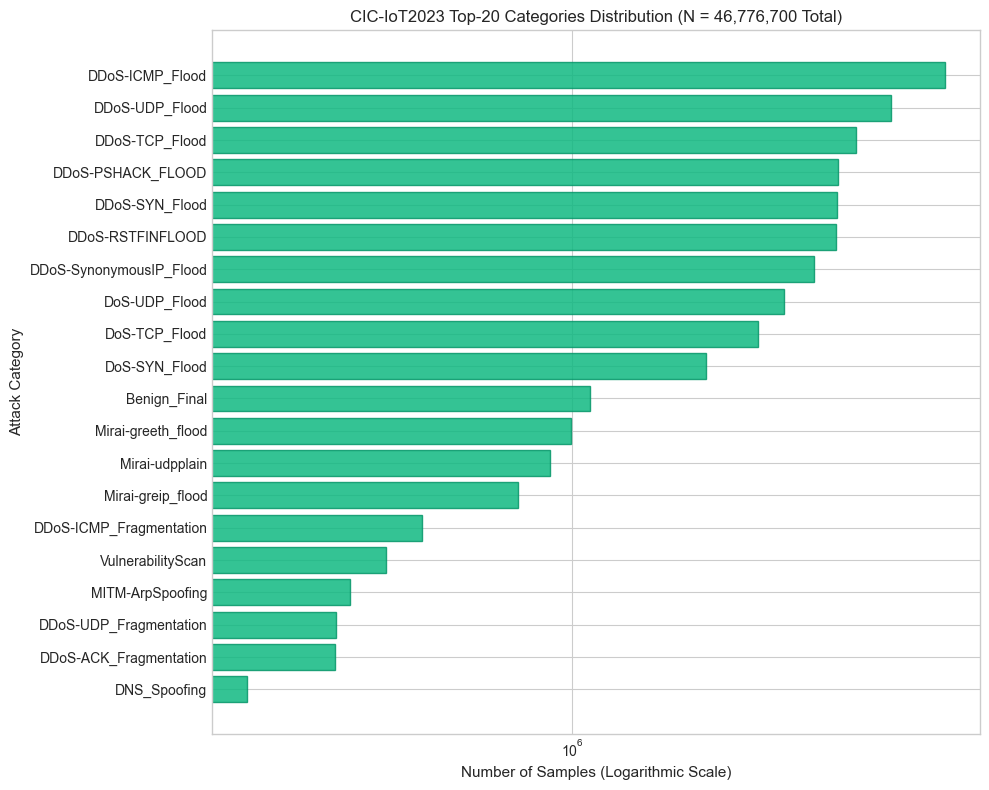

In [16]:
# Top-20 Category Bar Chart (Log-Scaled)
fig, ax = plt.subplots(figsize=(10, 8))
cats = iot_dist_df["Category"][::-1]
cnts = iot_dist_df["Count"][::-1]

ax.barh(cats, cnts, color="#10B981", edgecolor="#059669", alpha=0.85)
ax.set_xscale("log")
ax.set_xlabel("Number of Samples (Logarithmic Scale)")
ax.set_ylabel("Attack Category")
ax.set_title("CIC-IoT2023 Top-20 Categories Distribution (N = 46,776,700 Total)")
plt.tight_layout()
plt.show()

### B.6 Feature Distributions for Selected IoT Traffic Attributes

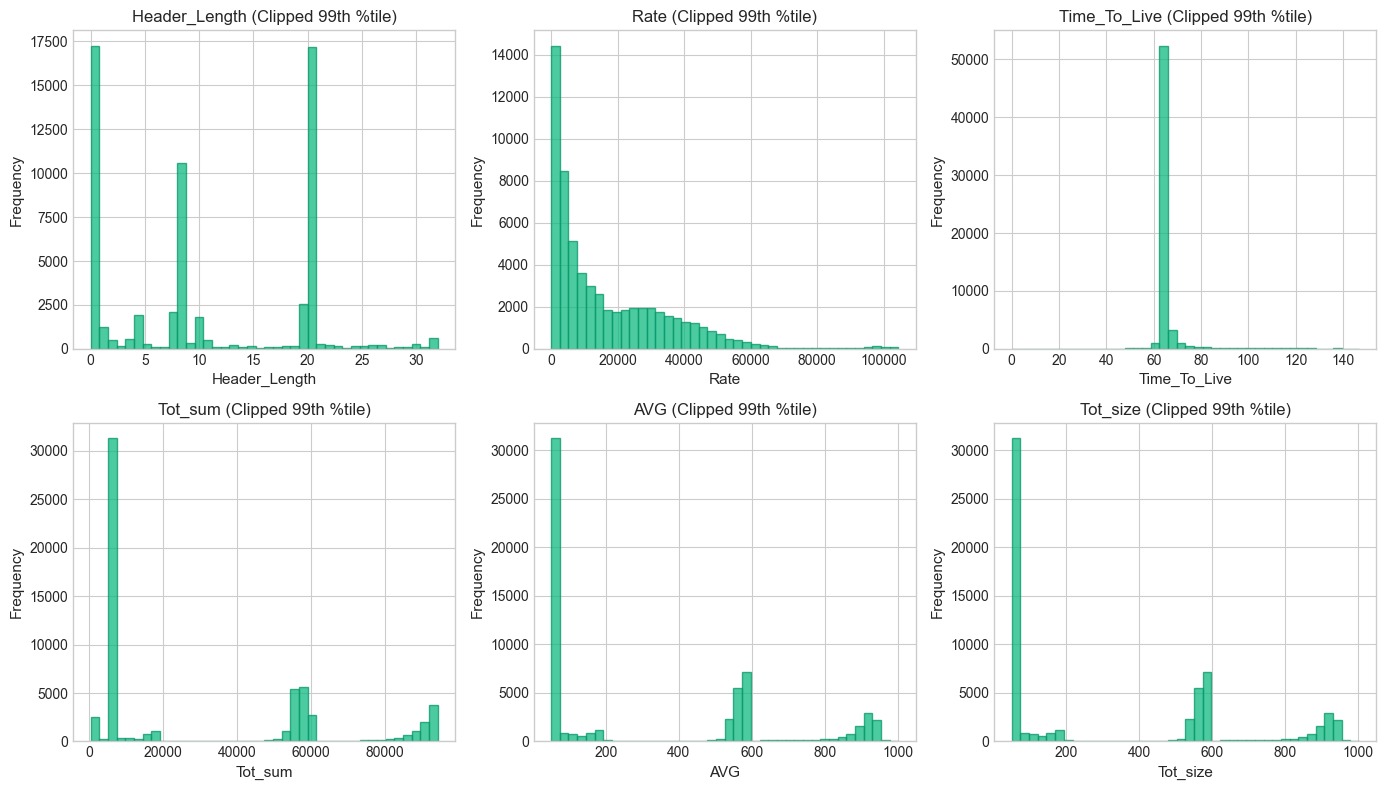

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(key_iot_features):
    s = ciciot_df_clean[col].dropna()
    upper = s.quantile(0.99)
    lower = s.min()
    s_clipped = s[(s >= lower) & (s <= upper)]
    axes[i].hist(s_clipped, bins=40, color="#10B981", edgecolor="#059669", alpha=0.75)
    axes[i].set_title(f"{col} (Clipped 99th %tile)")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### B.7 Correlation Analysis (Selected IoT Traffic Features)

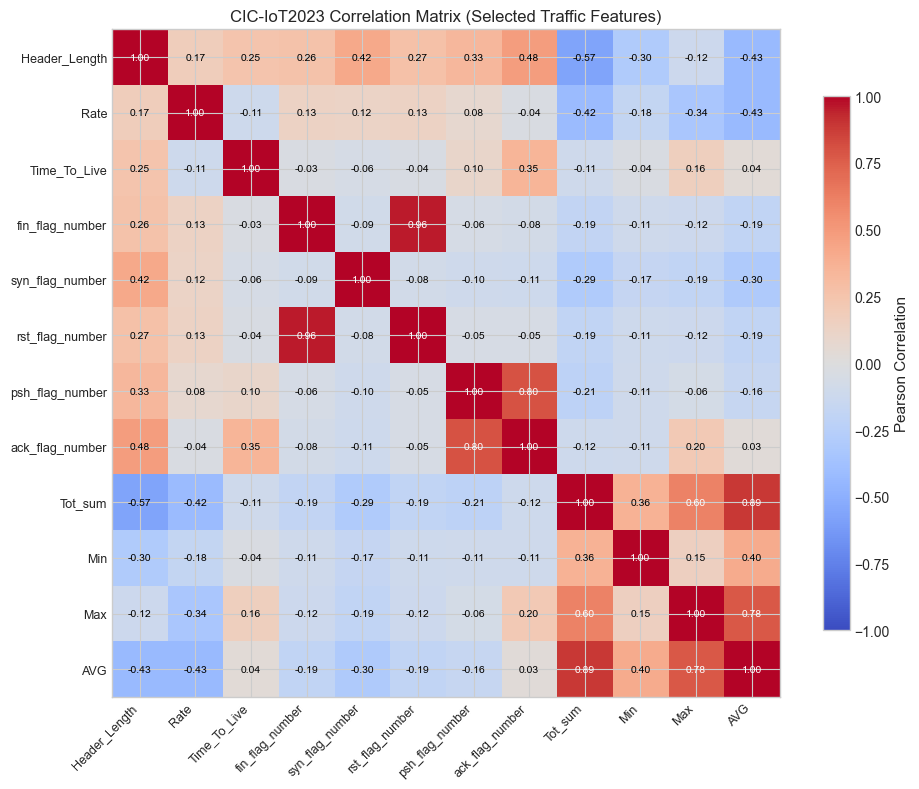

In [18]:
corr_features_iot = [
    "Header_Length", "Rate", "Time_To_Live", "fin_flag_number",
    "syn_flag_number", "rst_flag_number", "psh_flag_number",
    "ack_flag_number", "Tot_sum", "Min", "Max", "AVG"
]

corr_matrix_iot = ciciot_df_clean[corr_features_iot].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_matrix_iot, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_features_iot)))
ax.set_yticks(range(len(corr_features_iot)))
ax.set_xticklabels(corr_features_iot, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(corr_features_iot, fontsize=9)

for i in range(len(corr_features_iot)):
    for j in range(len(corr_features_iot)):
        val = corr_matrix_iot.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                color="white" if abs(val) > 0.6 else "black", fontsize=7.5)

fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson Correlation")
ax.set_title("CIC-IoT2023 Correlation Matrix (Selected Traffic Features)")
plt.tight_layout()
plt.show()

### B.8 Written Interpretation of CIC-IoT2023 Findings
1. **Reverse Imbalance:** In contrast to enterprise datasets, benign traffic is rare (2.35%), and volumetric floods (DDoS/DoS) dominate (>85% of records). For our Autoencoder (which trains on benign traffic to learn baseline reconstruction), we must deliberately sample from `Benign_Final` records to construct clean reconstruction training splits.
2. **Feature Schema Differentiation:** CIC-IoT2023 features are distinct from CICIDS2017 (39 IoT metrics vs 78 enterprise flow metrics). Concatenating them into a single tabular matrix without domain adaptation is invalid. The two datasets should be trained as distinct domain models or evaluated under a standardized flow abstraction.
3. **Absence of Inf/Missing Data:** The CIC-IoT2023 dataset demonstrates cleaner data pipelines with zero infinite/missing values in our sample.

---
# Part C: Summary & Implications for FT-Transformer + Autoencoder

| Aspect | CICIDS2017 | CIC-IoT2023 |
| :--- | :--- | :--- |
| **Total Records** | 2,830,743 | 46,776,700 |
| **Numeric Features** | 78 flow features | 39 traffic features |
| **Target Column** | `Label` (native) | `Attack_Category` (derived from directory) |
| **Distinct Classes** | 15 classes | 34 classes |
| **Benign vs Attack** | 80.3% Benign / 19.7% Attack | 2.35% Benign / 97.65% Attack |
| **Data Quality Issues** | Inf in flow rates, ~9% duplicates | Clean, minimal duplicates |
| **FT-Transformer Strategy** | Supervised 15-class classification | Supervised 34-class classification |
| **Autoencoder Strategy** | Train on benign traffic ($N \approx 1.8M$) | Train on `Benign_Final` ($N \approx 800k$) |

### Conclusion & Next Steps for Model Training (Week 7):
- Stratify splits 70% Train / 15% Val / 15% Test.
- Fit encoders and scalers strictly on training splits to prevent data leakage.
- FT-Transformer will learn tabular feature embeddings and classify known attacks.
- Autoencoder will score reconstruction errors to flag anomalous and unseen threats.